# Elliptic Bitcoin Dataset: Exploratory Data Analysis

**Contributor:** Nandini Elangovan

This notebook examines class prevalence, transaction features, graph structure, feature importance, and temporal drift. Expensive steps use bounded, deterministic samples; train, validation, and test periods remain chronological.

In [42]:
from pathlib import Path
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
RANDOM_STATE = 207
DATA_DIR = Path('elliptic_bitcoin_dataset')
FEATURES_PATH = DATA_DIR / 'elliptic_txs_features.csv'
CLASSES_PATH = DATA_DIR / 'elliptic_txs_classes.csv'
EDGES_PATH = DATA_DIR / 'elliptic_txs_edgelist.csv'
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 13, 'axes.labelsize': 10})


## Load and Prepare

The data is reloaded from the original CSVs so this notebook can run independently of `data_preprocessing.ipynb`. Unknown labels are retained in the node table and graph but excluded from supervised label summaries.

In [43]:
feature_columns = ['txId', 'time_step'] + [f'feature_{i}' for i in range(1, 166)]
features = pd.read_csv(FEATURES_PATH, header=None, names=feature_columns)
classes = pd.read_csv(CLASSES_PATH, dtype={'class': 'string'})
edges = pd.read_csv(EDGES_PATH)
assert features.shape[1] == 167, f'Expected 167 feature columns; found {features.shape[1]}'
assert {'txId', 'class'}.issubset(classes.columns)
assert {'txId1', 'txId2'}.issubset(edges.columns)
assert not features['txId'].duplicated().any()
label_map = {'1': 1, '2': 0}
classes['target'] = classes['class'].map(label_map)
data = features.merge(classes[['txId', 'target']], on='txId', how='left', validate='one_to_one')
data['target'] = data['target'].astype('float64')
feature_cols = [f'feature_{i}' for i in range(1, 166)]
labeled = data.loc[data['target'].notna()].copy()
labeled['target'] = labeled['target'].astype('int8')
train = labeled.loc[labeled['time_step'] <= 34].copy()
validation = labeled.loc[labeled['time_step'].between(35, 41)].copy()
test = labeled.loc[labeled['time_step'] >= 42].copy()
print(f'Nodes: {len(data):,} | labeled: {len(labeled):,} | edges: {len(edges):,}')
print(f'Train: {len(train):,} | validation: {len(validation):,} | test: {len(test):,}')
print('Label counts (1=illicit, 0=licit):')
display(labeled['target'].value_counts().sort_index().rename(index={0: 'licit', 1: 'illicit'}))
train_corr = train[feature_cols].corrwith(train['target']).replace([np.inf, -np.inf], np.nan).dropna()
train_corr = train_corr.reindex(train_corr.abs().sort_values(ascending=False).index)
top_corr_features = train_corr.head(15).index.tolist()
print('Feature matrix:', len(feature_cols), 'numeric predictors; target and identifiers excluded.')

Nodes: 203,769 | labeled: 46,564 | edges: 234,355
Train: 29,894 | validation: 7,829 | test: 8,841
Label counts (1=illicit, 0=licit):


target
licit      42019
illicit     4545
Name: count, dtype: int64

Feature matrix: 165 numeric predictors; target and identifiers excluded.


## 1. Target and Time Overview

First establish how the observed class mix and labeled transaction volume change over the timeline and across the chronological evaluation periods.

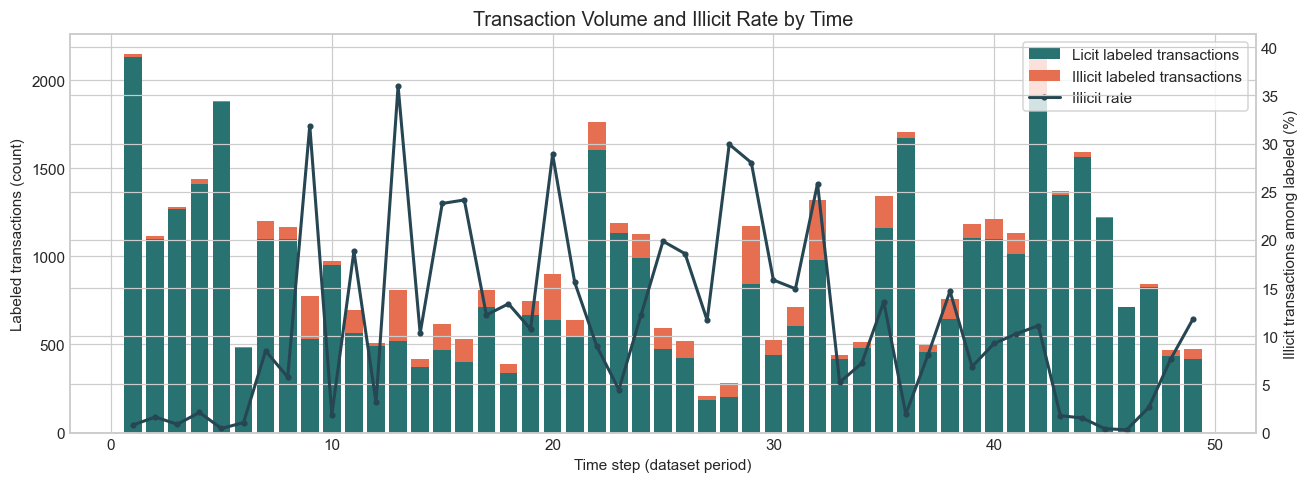

In [ ]:
by_time = labeled.groupby(['time_step', 'target']).size().unstack(fill_value=0).reindex(columns=[0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(by_time.index, by_time[0], label='Licit labeled transactions', color='#287271')
ax.bar(by_time.index, by_time[1], bottom=by_time[0], label='Illicit labeled transactions', color='#e76f51')
ax.set(xlabel='Time step (dataset period)', ylabel='Labeled transactions (count)', title='Transaction Volume and Illicit Rate by Time')
ax2 = ax.twinx()
rate = by_time[1].div(by_time.sum(axis=1).replace(0, np.nan)).mul(100)
ax2.plot(by_time.index, rate, color='#264653', linewidth=2, marker='.', label='Illicit rate')
ax2.set_ylabel('Illicit transactions among labeled (%)')
ax2.set_ylim(0, max(15, float(rate.max()) * 1.15))
handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax.legend(handles1 + handles2, labels1 + labels2, loc='upper right', frameon=True)
fig.tight_layout(); plt.show()

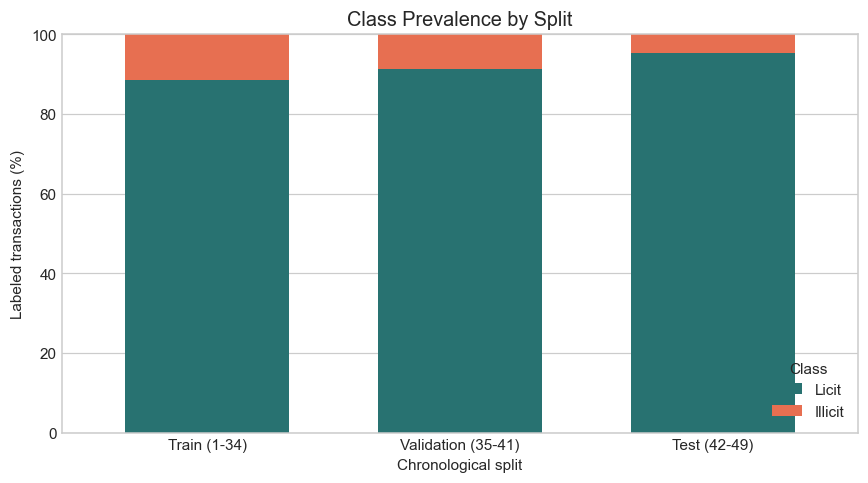

In [ ]:
split_frames = {'Train (1-34)': train, 'Validation (35-41)': validation, 'Test (42-49)': test}
split_rates = pd.DataFrame({name: frame['target'].value_counts(normalize=True).reindex([0, 1], fill_value=0).mul(100) for name, frame in split_frames.items()}).T
split_rates.columns = ['Licit', 'Illicit']
ax = split_rates.plot(kind='bar', stacked=True, color=['#287271', '#e76f51'], figsize=(8, 4.5), width=0.65)
ax.set(xlabel='Chronological split', ylabel='Labeled transactions (%)', title='Class Prevalence by Split')
ax.set_ylim(0, 100); ax.legend(title='Class', loc='lower right'); ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()


## 2. Feature Distributions

The supplied features are numeric but need not share comparable distributions. Distribution summaries and class-conditioned plots below use training data to select features; this keeps exploratory feature selection from peeking at held-out labels.

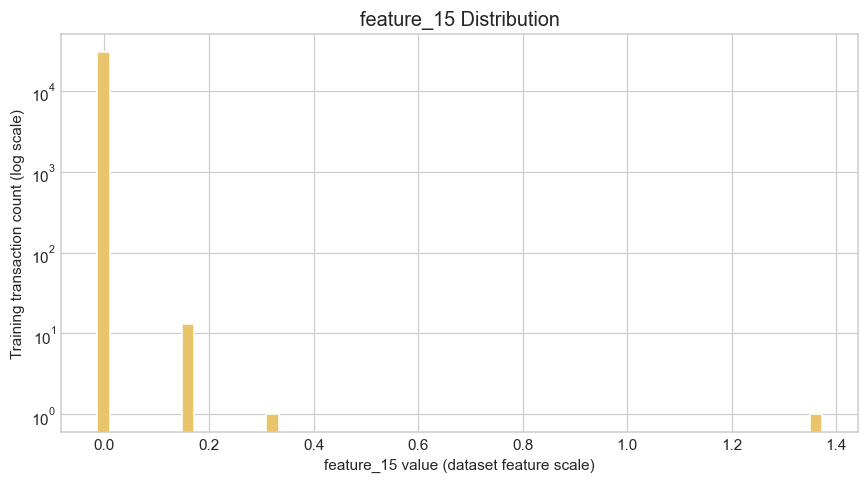

In [39]:
abs_skew = train[feature_cols].skew().abs().replace([np.inf, -np.inf], np.nan).dropna()
heavy_feature = abs_skew.idxmax()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(train[heavy_feature].dropna(), bins=60, color='#e9c46a', edgecolor='white')
ax.set_yscale('log')
ax.set(xlabel=f'{heavy_feature} value (dataset feature scale)', ylabel='Training transaction count (log scale)', title=f'{heavy_feature} Distribution')
fig.tight_layout(); plt.show()


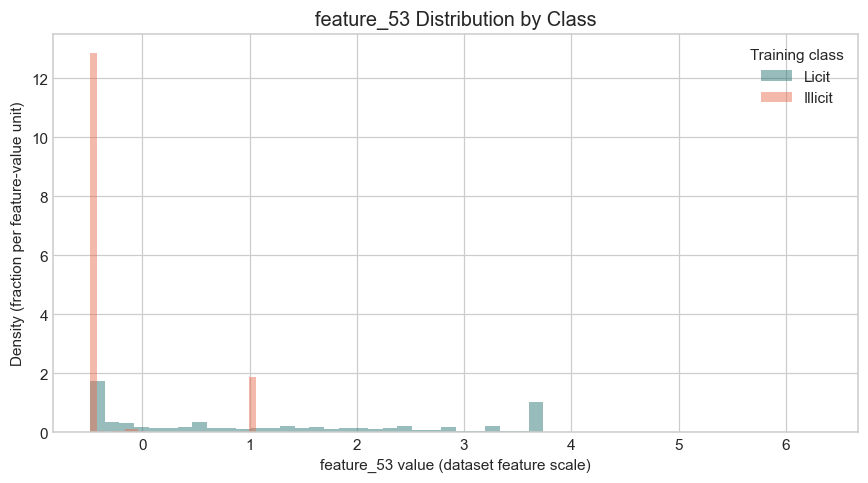

In [ ]:
class_feature = train_corr.index[0]
fig, ax = plt.subplots(figsize=(8, 4.5))
for target_value, label, color in [(0, 'Licit', '#287271'), (1, 'Illicit', '#e76f51')]:
    values = train.loc[train['target'] == target_value, class_feature].dropna()
    ax.hist(values, bins=50, density=True, alpha=0.48, label=label, color=color)
ax.set(xlabel=f'{class_feature} value (dataset feature scale)', ylabel='Density (fraction per feature-value unit)', title=f'{class_feature} Distribution by Class')
ax.legend(title='Training class'); fig.tight_layout(); plt.show()


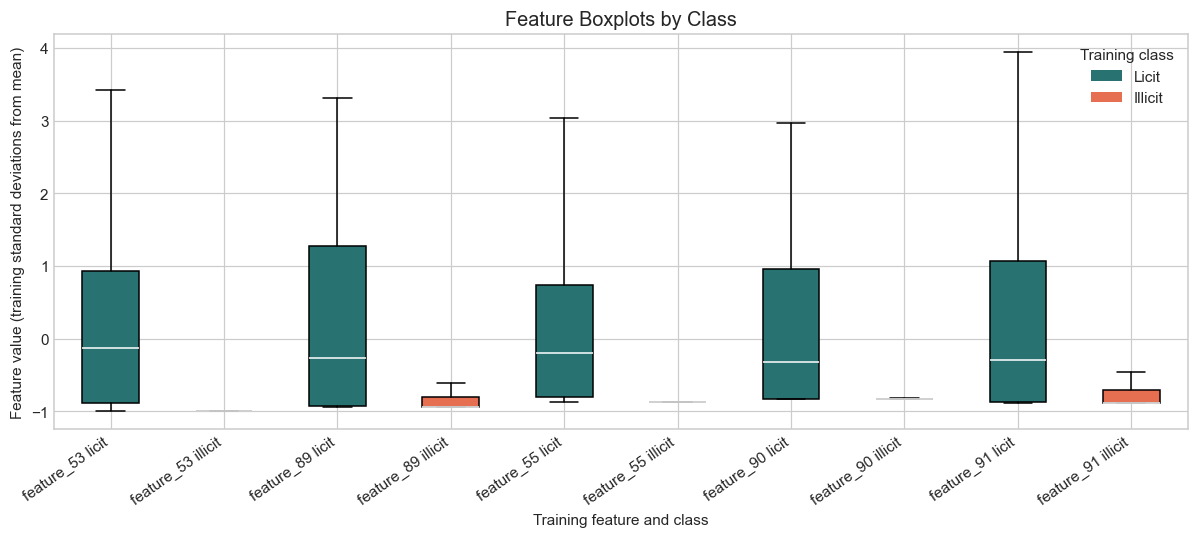

In [40]:
box_features = train_corr.head(5).index.tolist()
fig, ax = plt.subplots(figsize=(11, 5))
box_values, box_labels = [], []
for feature in box_features:
    mean = train[feature].mean(); std = train[feature].std()
    scale = std if pd.notna(std) and std > 0 else 1.0
    for target_value, class_name in [(0, 'licit'), (1, 'illicit')]:
        vals = ((train.loc[train['target'] == target_value, feature] - mean) / scale).dropna()
        box_values.append(vals.to_numpy()); box_labels.append(feature + ' ' + class_name)
box_plot = ax.boxplot(box_values, showfliers=False, patch_artist=True, medianprops={'color': 'white'})
for patch, label in zip(box_plot['boxes'], box_labels):
    patch.set_facecolor('#287271' if label.endswith(' licit') else '#e76f51')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor='#287271', label='Licit'), Patch(facecolor='#e76f51', label='Illicit')], title='Training class')
ax.set_xticks(range(1, len(box_labels) + 1), box_labels, rotation=35, ha='right')
ax.set(xlabel='Training feature and class', ylabel='Feature value (training standard deviations from mean)', title='Feature Boxplots by Class')
fig.tight_layout(); plt.show()


## 3. Correlations

Correlation ranks are univariate screening tools, not proof of predictive or causal value. All target correlations below are computed on the labeled training period only.

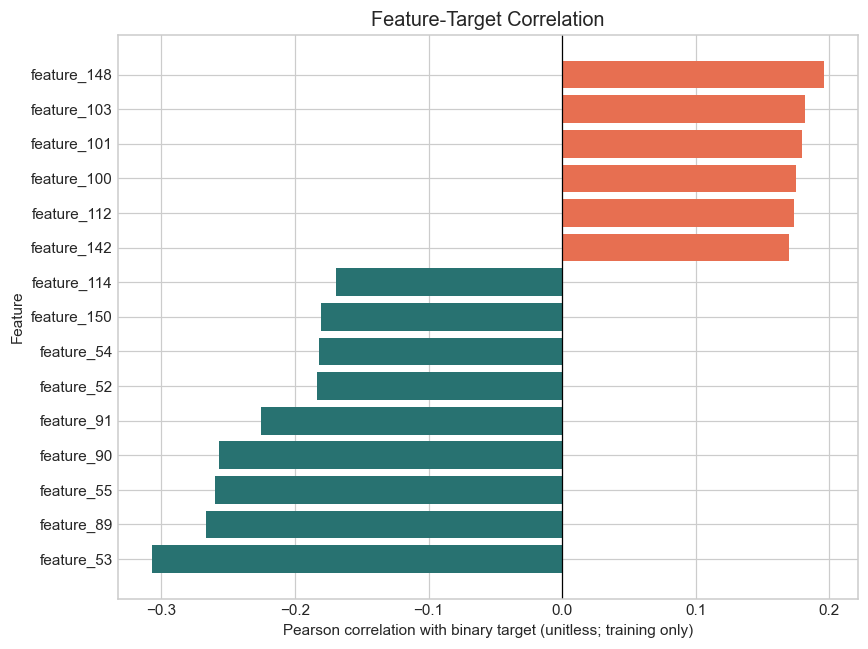

In [ ]:
ranked = train_corr.head(15).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
colors = ['#287271' if value < 0 else '#e76f51' for value in ranked.values]
ax.barh(ranked.index, ranked.values, color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set(xlabel='Pearson correlation with binary target (unitless; training only)', ylabel='Feature', title='Feature-Target Correlation')
fig.tight_layout(); plt.show()


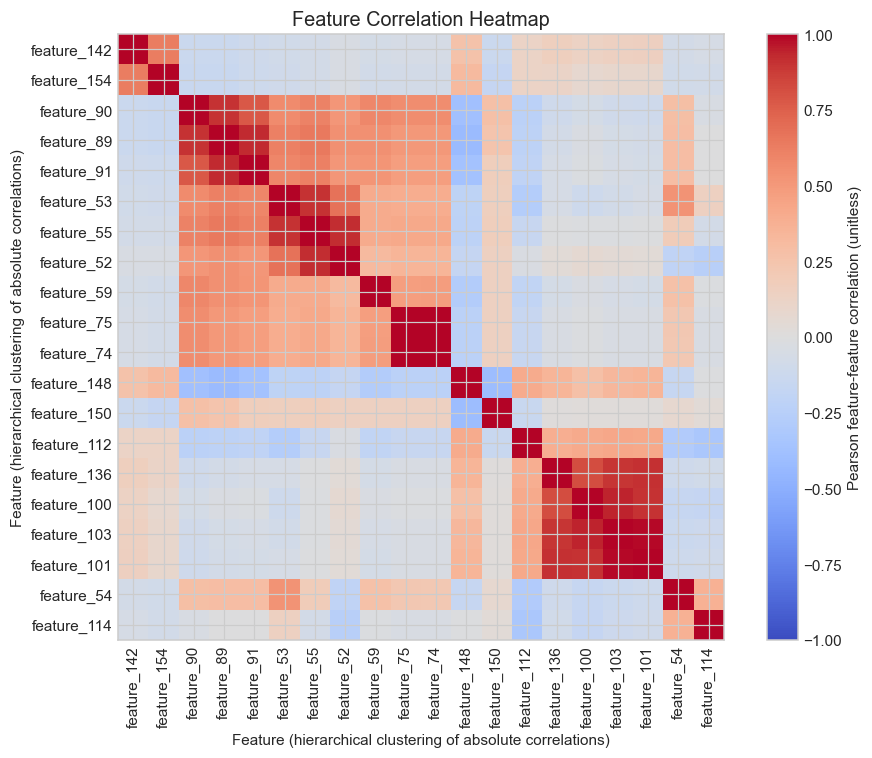

In [ ]:
heat_features = train_corr.head(20).index.tolist()
corr_matrix = train[heat_features].corr().fillna(0)
distance = (1 - corr_matrix.abs()).clip(0, 1)
np.fill_diagonal(distance.values, 0)
try:
    from scipy.cluster.hierarchy import leaves_list, linkage
    from scipy.spatial.distance import squareform
    order = leaves_list(linkage(squareform(distance.to_numpy(), checks=False), method='average'))
    order_note = 'hierarchical clustering of absolute correlations'
except ImportError:
    order = np.argsort(-corr_matrix.abs().mean().to_numpy())
    order_note = 'descending mean absolute correlation (SciPy unavailable)'
ordered = corr_matrix.iloc[order, order]
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(ordered, cmap='coolwarm', vmin=-1, vmax=1, interpolation='nearest')
ax.set_xticks(range(len(ordered)), ordered.columns, rotation=90); ax.set_yticks(range(len(ordered)), ordered.index)
ax.set(xlabel='Feature (' + order_note + ')', ylabel='Feature (' + order_note + ')', title='Feature Correlation Heatmap')
fig.colorbar(image, ax=ax, label='Pearson feature-feature correlation (unitless)')
fig.tight_layout(); plt.show()


## 4. Graph Insights

Edges are directed transaction links. Homophily is calculated only when both endpoint labels are known; degree is calculated on the full graph, retaining unlabeled nodes.

In [10]:
tx_to_node = pd.Series(np.arange(len(data), dtype=np.int64), index=data['txId']).to_dict()
source_idx = edges['txId1'].map(tx_to_node)
target_idx = edges['txId2'].map(tx_to_node)
valid_edges = source_idx.notna() & target_idx.notna()
source_idx = source_idx.loc[valid_edges].astype('int64').to_numpy()
target_idx = target_idx.loc[valid_edges].astype('int64').to_numpy()
n_nodes = len(data)
out_degree = np.bincount(source_idx, minlength=n_nodes)
in_degree = np.bincount(target_idx, minlength=n_nodes)
node_labels = data['target'].to_numpy()
known_edge = ~np.isnan(node_labels[source_idx]) & ~np.isnan(node_labels[target_idx])
same_class = node_labels[source_idx[known_edge]] == node_labels[target_idx[known_edge]]
print(f'Edges mapped to graph nodes: {len(source_idx):,} / {len(edges):,}')
print(f'Edges with two known labels: {known_edge.sum():,}')

Edges mapped to graph nodes: 234,355 / 234,355
Edges with two known labels: 36,624


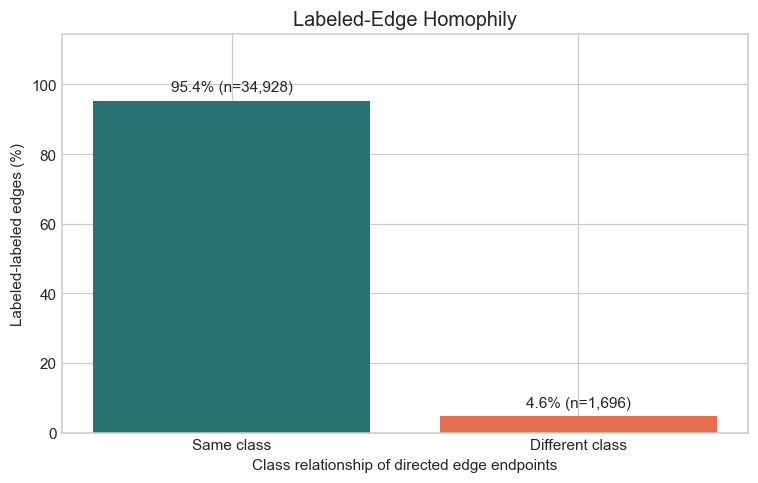

In [30]:
homophily_counts = pd.Series({'Same class': int(same_class.sum()), 'Different class': int((~same_class).sum())})
homophily_pct = homophily_counts.div(homophily_counts.sum()).mul(100)
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(homophily_pct.index, homophily_pct.values, color=['#287271', '#e76f51'])
ax.bar_label(bars, labels=[f'{p:.1f}% (n={n:,})' for p, n in zip(homophily_pct, homophily_counts)], padding=4)
ax.set(xlabel='Class relationship of directed edge endpoints', ylabel='Labeled-labeled edges (%)', title='Labeled-Edge Homophily')
ax.set_ylim(0, max(100, float(homophily_pct.max()) * 1.2)); fig.tight_layout(); plt.show()


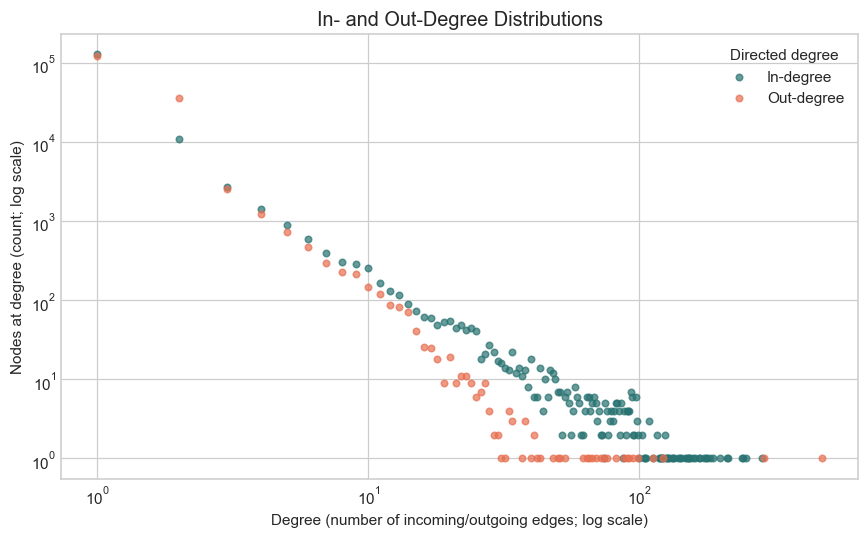

In [31]:
fig, ax = plt.subplots(figsize=(8, 5))
for values, label, color in [(in_degree, 'In-degree', '#287271'), (out_degree, 'Out-degree', '#e76f51')]:
    positive = values[values > 0]
    counts = pd.Series(positive).value_counts().sort_index()
    ax.scatter(counts.index, counts.values, s=18, alpha=0.7, label=label, color=color)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set(xlabel='Degree (number of incoming/outgoing edges; log scale)', ylabel='Nodes at degree (count; log scale)', title='In- and Out-Degree Distributions')
ax.legend(title='Directed degree'); fig.tight_layout(); plt.show()
zero_in = int((in_degree == 0).sum()); zero_out = int((out_degree == 0).sum())


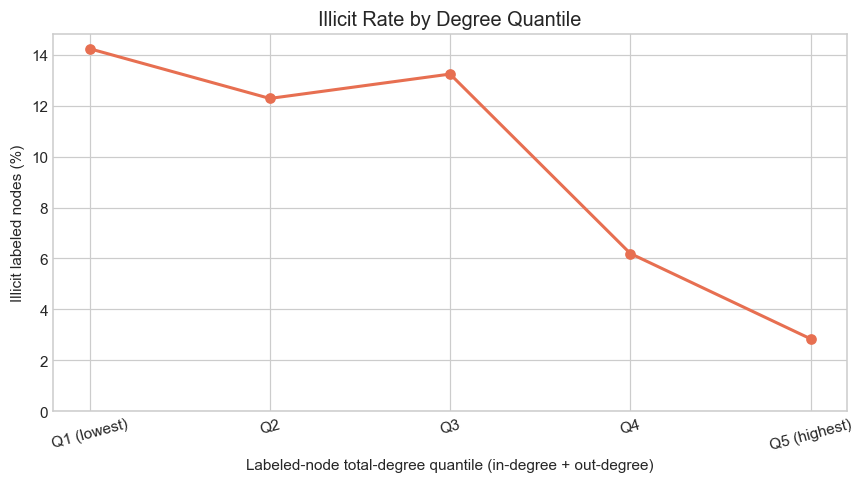

In [32]:
labeled_node_idx = data.index[data['target'].notna()].to_numpy()
degree_score = in_degree[labeled_node_idx] + out_degree[labeled_node_idx]
degree_frame = pd.DataFrame({'degree': degree_score, 'target': data.loc[labeled_node_idx, 'target'].astype(int).to_numpy()})
degree_frame['degree_group'] = pd.qcut(degree_frame['degree'].rank(method='first'), q=5, labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4', 'Q5 (highest)'])
degree_rate = degree_frame.groupby('degree_group', observed=False)['target'].agg(['mean', 'size'])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(degree_rate.index.astype(str), degree_rate['mean'] * 100, marker='o', color='#e76f51', linewidth=2)
ax.set(xlabel='Labeled-node total-degree quantile (in-degree + out-degree)', ylabel='Illicit labeled nodes (%)', title='Illicit Rate by Degree Quantile')
ax.set_ylim(bottom=0); ax.tick_params(axis='x', rotation=15); fig.tight_layout(); plt.show()


## 5. Feature Importance

The model is fit only on a bounded stratified sample from training. Permutation importance is measured on validation data using average precision, suitable for an imbalanced positive class; the test period is not used for model fitting or feature selection.

In [ ]:
per_class_limit = 6000
train_sample = pd.concat([train.loc[train['target'] == cls].sample(n=min(per_class_limit, int((train['target'] == cls).sum())), random_state=RANDOM_STATE) for cls in [0, 1]])
validation_sample = validation.sample(n=min(2500, len(validation)), random_state=RANDOM_STATE)
model = RandomForestClassifier(n_estimators=80, max_depth=16, min_samples_leaf=3, max_features='sqrt', class_weight='balanced_subsample', n_jobs=-1, random_state=RANDOM_STATE)
model.fit(train_sample[feature_cols], train_sample['target'])
perm = permutation_importance(model, validation_sample[feature_cols], validation_sample['target'], scoring='average_precision', n_repeats=2, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=feature_cols).sort_values(ascending=False)
from sklearn.metrics import average_precision_score
validation_scores = model.predict_proba(validation_sample[feature_cols])[:, 1]
print(f'Fit rows: {len(train_sample):,}; validation rows for permutation: {len(validation_sample):,}')
print(f'Validation average precision: {average_precision_score(validation_sample.target, validation_scores):.3f}')

/opt/homebrew/Caskroom/miniconda/base/envs/ml/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/opt/homebrew/Caskroom/miniconda/base/envs/ml/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/opt/homebrew/Caskroom/miniconda/base/envs/ml/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as earl

Fit rows: 9,462; validation rows for permutation: 2,500
Validation average precision: 0.940


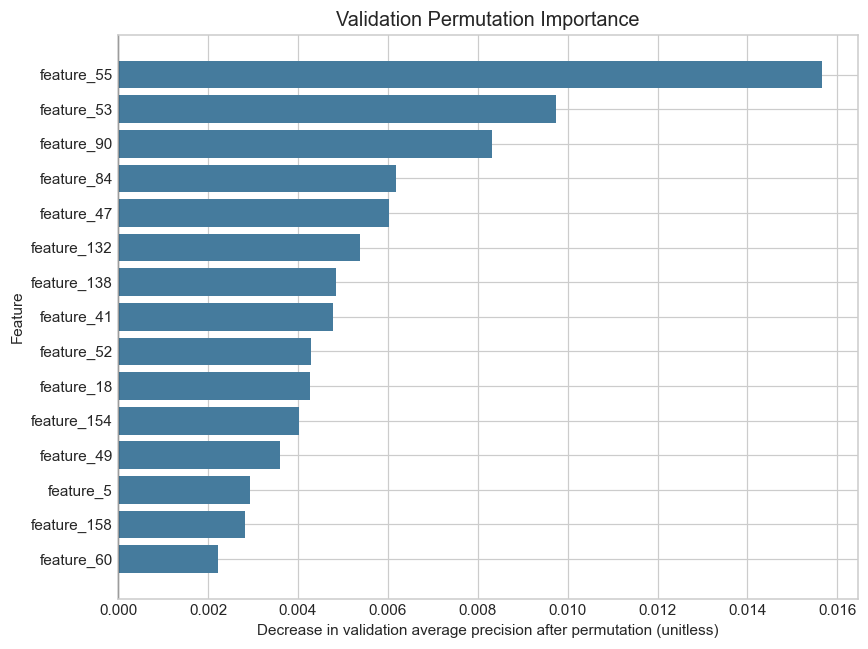

In [33]:
top_importance = importance.head(15).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_importance.index, top_importance.values, color='#457b9d')
ax.axvline(0, color='black', linewidth=0.8)
ax.set(xlabel='Decrease in validation average precision after permutation (unitless)', ylabel='Feature', title='Validation Permutation Importance')
fig.tight_layout(); plt.show()


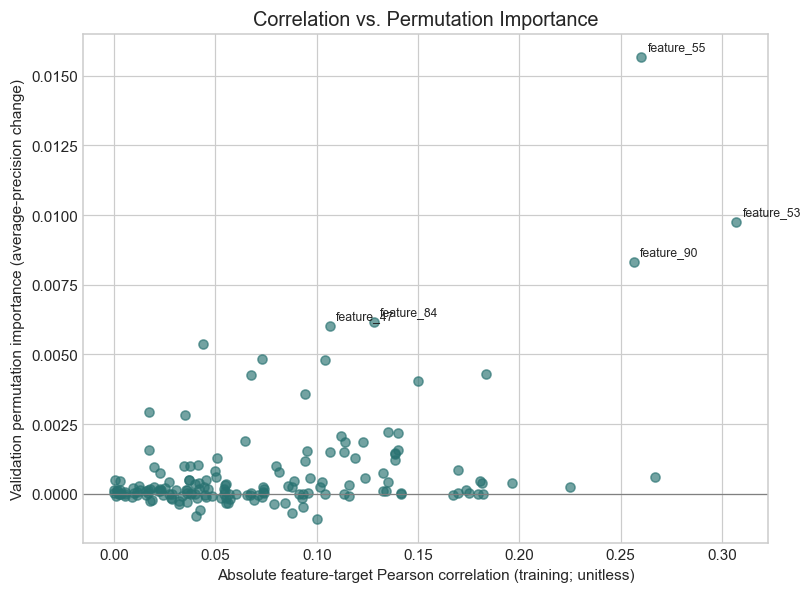

In [34]:
comparison = pd.DataFrame({'abs_train_correlation': train_corr.abs(), 'validation_permutation_importance': importance}).dropna()
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(comparison['abs_train_correlation'], comparison['validation_permutation_importance'], alpha=0.65, color='#287271')
for feature in importance.head(5).index:
    if feature in comparison.index:
        ax.annotate(feature, (comparison.loc[feature, 'abs_train_correlation'], comparison.loc[feature, 'validation_permutation_importance']), xytext=(4, 4), textcoords='offset points', fontsize=8)
ax.axhline(0, color='gray', linewidth=0.8)
ax.set(xlabel='Absolute feature-target Pearson correlation (training; unitless)', ylabel='Validation permutation importance (average-precision change)', title='Correlation vs. Permutation Importance')
fig.tight_layout(); plt.show()


## 6. Temporal Drift

Feature drift is summarized across all transactions because labels are not needed to observe feature distributions. Standardization baselines and PCA are fit using training-period features only; later periods are transformed, not used to fit those summaries.

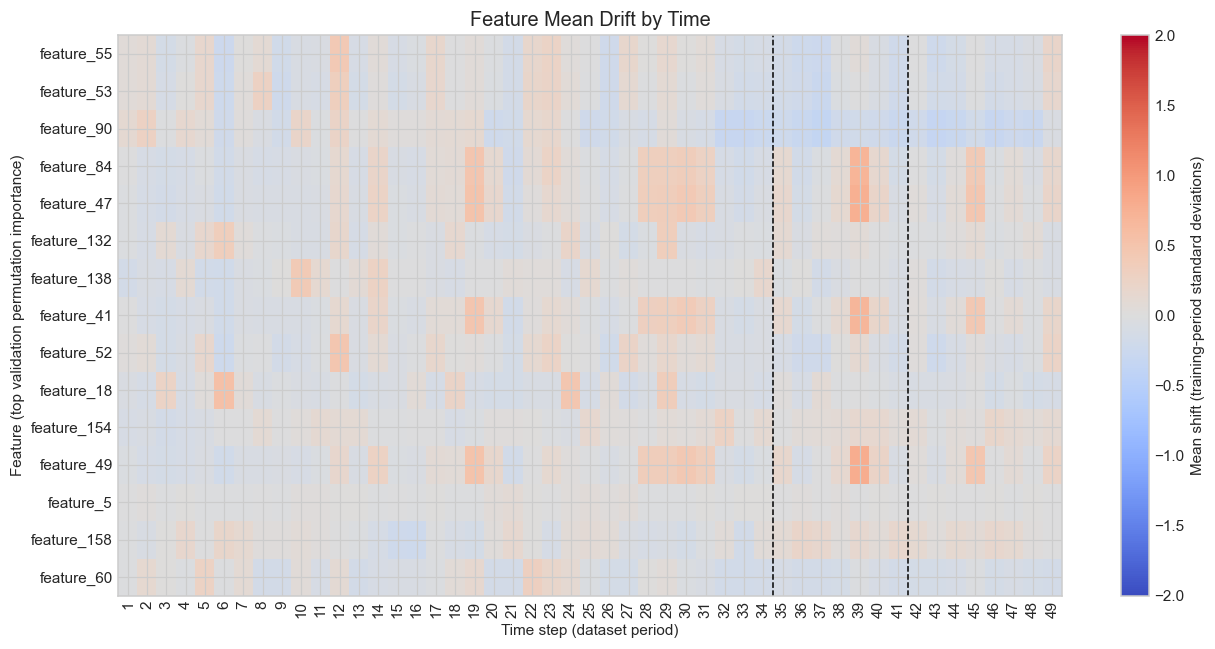

In [ ]:
drift_features = importance.head(15).index.tolist()
training_period = data.loc[data['time_step'] <= 34, drift_features]
baseline_mean = training_period.mean()
baseline_std = training_period.std().replace(0, np.nan)
time_means = data.groupby('time_step')[drift_features].mean()
drift_z = time_means.subtract(baseline_mean, axis='columns').div(baseline_std, axis='columns').fillna(0)
fig, ax = plt.subplots(figsize=(12, 6))
image = ax.imshow(drift_z.T, aspect='auto', cmap='coolwarm', vmin=-2, vmax=2, interpolation='nearest')
ax.set_xticks(range(len(drift_z.index)), drift_z.index, rotation=90)
ax.set_yticks(range(len(drift_features)), drift_features)
ax.set(xlabel='Time step (dataset period)', ylabel='Feature (top validation permutation importance)', title='Feature Mean Drift by Time')
for boundary in [34.5, 41.5]:
    if drift_z.index.min() <= boundary <= drift_z.index.max(): ax.axvline(boundary - drift_z.index.min(), color='black', linestyle='--', linewidth=1)
fig.colorbar(image, ax=ax, label='Mean shift (training-period standard deviations)')
fig.tight_layout(); plt.show()


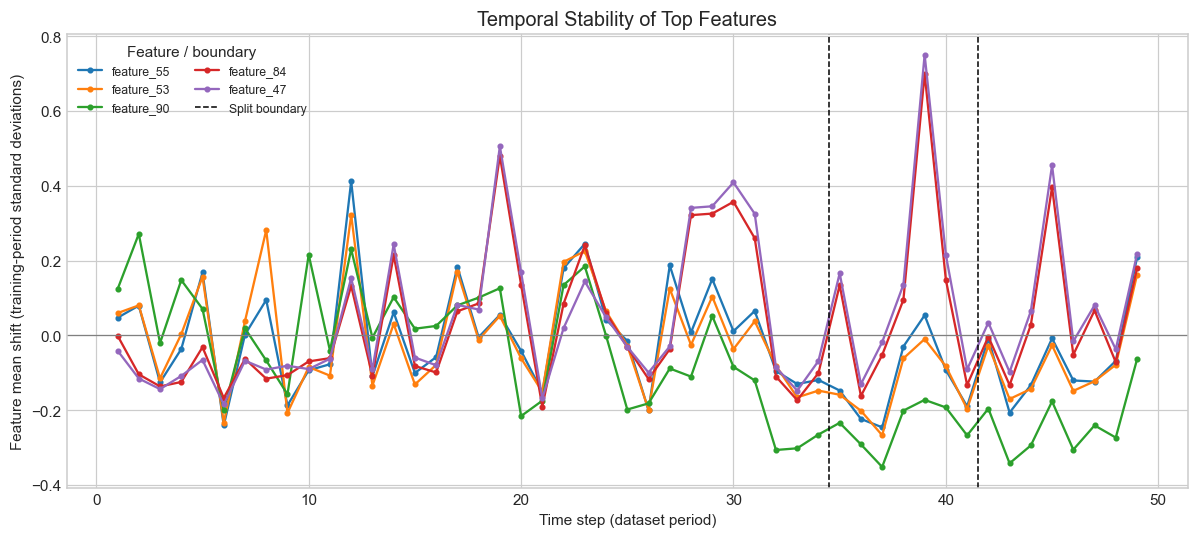

In [ ]:
stable_features = importance.head(5).index.tolist()
fig, ax = plt.subplots(figsize=(11, 5))
for feature in stable_features:
    ax.plot(time_means.index, (time_means[feature] - baseline_mean[feature]) / (baseline_std[feature] if pd.notna(baseline_std[feature]) else 1), marker='.', linewidth=1.5, label=feature)
for boundary in [34.5, 41.5]: ax.axvline(boundary, color='black', linestyle='--', linewidth=1, label='Split boundary' if boundary == 34.5 else None)
ax.axhline(0, color='gray', linewidth=0.8)
ax.set(xlabel='Time step (dataset period)', ylabel='Feature mean shift (training-period standard deviations)', title='Temporal Stability of Top Features')
ax.legend(title='Feature / boundary', ncol=2, fontsize=8); fig.tight_layout(); plt.show()


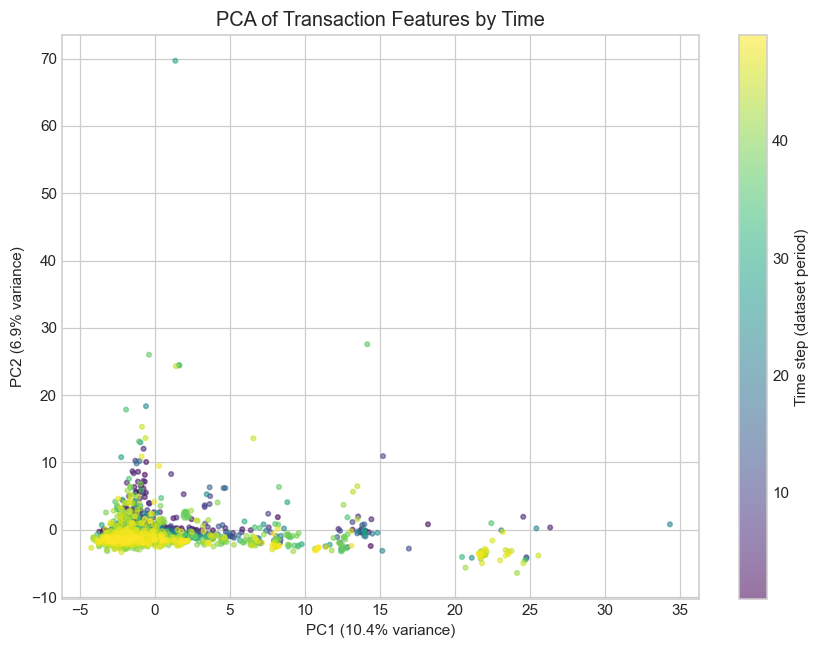

In [41]:
pca_features = feature_cols
train_period = data.loc[data['time_step'] <= 34]
val_period = data.loc[data['time_step'].between(35, 41)]
test_period = data.loc[data['time_step'] >= 42]
sampled_parts = [frame.sample(n=min(1200, len(frame)), random_state=RANDOM_STATE) for frame in [train_period, val_period, test_period] if len(frame)]
pca_sample = pd.concat(sampled_parts, axis=0).sort_index()
pca_train = train_period.sample(n=min(5000, len(train_period)), random_state=RANDOM_STATE)
pca_mean = train_period[pca_features].mean()
pca_std = train_period[pca_features].std().replace(0, np.nan).fillna(1)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca.fit((pca_train[pca_features] - pca_mean) / pca_std)
projection = pca.transform((pca_sample[pca_features] - pca_mean) / pca_std)
fig, ax = plt.subplots(figsize=(8, 6))
points = ax.scatter(projection[:, 0], projection[:, 1], c=pca_sample['time_step'], cmap='viridis', s=9, alpha=0.55)
ax.set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% variance)', ylabel=f'PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% variance)', title='PCA of Transaction Features by Time')
fig.colorbar(points, ax=ax, label='Time step (dataset period)')
fig.tight_layout(); plt.show()
